# Neural Network untuk Denoising, Demosaicking, dan Texture
Tujuan:
- Memahami cara kerja denoising, demosaicking, dan texture
- Mengimplementasikan denoising, demosaicking, dan texture dengan neural network

Target:
- Cara kerja dapat dipahami

Catatan:
- Tiap bagian dipisah ke cell berbeda.
- Citra diunduh dari internet dan diproses lokal.

In [1]:
import math
import urllib.request
import urllib.error
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
torch.manual_seed(42)

ROOT_DIR = Path(".")
ASSET_DIR = ROOT_DIR / "assets"
OUTPUT_DIR = ROOT_DIR / "outputs"
ASSET_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ── Multi-GPU setup (T4 x2) ─────────────────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_gpus = torch.cuda.device_count()
print(f"Device: {device}  |  GPUs available: {num_gpus}")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = True
    try:
        torch.set_float32_matmul_precision("high")
    except AttributeError:
        pass


def wrap_multi_gpu(model):
    """Wrap model with DataParallel if >1 GPU available."""
    if num_gpus > 1:
        model = nn.DataParallel(model)
    return model.to(device)


def download_image(url: str, filename: str) -> Path:
    dst = ASSET_DIR / filename
    if dst.exists() and dst.stat().st_size > 0:
        return dst

    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36",
        "Accept": "image/avif,image/webp,image/*,*/*;q=0.8",
    }
    req = urllib.request.Request(url, headers=headers)
    with urllib.request.urlopen(req, timeout=20) as resp:
        data = resp.read()
    dst.write_bytes(data)
    return dst


def read_image_bgr(path: Path, size=None) -> np.ndarray:
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img.ndim == 3 and img.shape[2] == 4:
        img = cv2.cvtColor(img, cv2.COLOR_BGRA2BGR)
    if size is not None:
        img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    return img


def bgr2rgb(img: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def rgb2bgr(img: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(img, cv2.COLOR_RGB2BGR)


def to_tensor(img_bgr: np.ndarray) -> torch.Tensor:
    img = img_bgr.astype(np.float32) / 255.0
    img = torch.from_numpy(img.transpose(2, 0, 1)).unsqueeze(0)
    return img


def to_numpy(img_tensor: torch.Tensor) -> np.ndarray:
    img = img_tensor.squeeze(0).permute(1, 2, 0).clamp(0, 1).cpu().numpy()
    return (img * 255.0).astype(np.uint8)


def show_images(title: str, images: list, labels: list, save_path=None) -> None:
    n = len(images)
    plt.figure(figsize=(4 * n, 4))
    for i, (img, label) in enumerate(zip(images, labels), start=1):
        ax = plt.subplot(1, n, i)
        if img.ndim == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(img)
        ax.set_title(label)
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved: {save_path}")


Device: cuda  |  GPUs available: 2


## 1) Denoising (DnCNN residual — upgraded)
Ide: gambar ber-noise $y = x + n$. Jaringan dilatih memprediksi noise $\hat{n} = f_\theta(y)$, sehingga hasil bersih $\hat{x} = y - \hat{n}$.

**Upgrade dari versi asal:**
- DnCNN lebih dalam: `depth=17`, `features=64` — sesuai paper asli DnCNN
- Loss gabungan: **L1 + MSE + SSIM** untuk detail tekstur & kecerahan sekaligus
- Training lebih lama: **5 000 steps** dengan `patch=192`, `batch=32` (T4 x2)
- **DataParallel** memanfaatkan kedua T4
- TTA (Test-Time Augmentation) 8× tetap dipakai untuk inferensi


[Denoiser] Step 500/5000  loss: 0.159314
[Denoiser] Step 1000/5000  loss: 0.129585
[Denoiser] Step 1500/5000  loss: 0.126389
[Denoiser] Step 2000/5000  loss: 0.129193
[Denoiser] Step 2500/5000  loss: 0.121290
[Denoiser] Step 3000/5000  loss: 0.140552
[Denoiser] Step 3500/5000  loss: 0.140304
[Denoiser] Step 4000/5000  loss: 0.123576
[Denoiser] Step 4500/5000  loss: 0.129557
[Denoiser] Step 5000/5000  loss: 0.124238
PSNR noisy: 20.78 dB  →  PSNR denoised: 22.48 dB


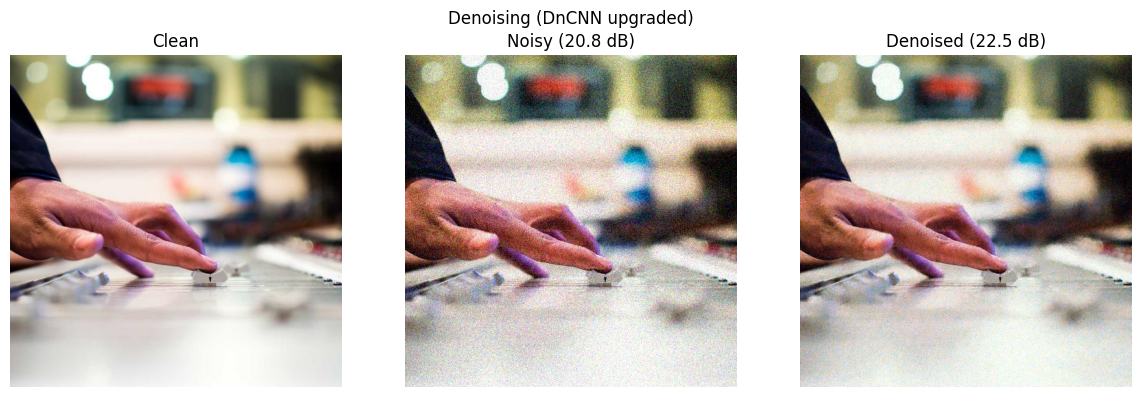

Saved: outputs/denoising_nn.png


In [2]:
import torch.nn.functional as F

# ── Dataset ──────────────────────────────────────────────────────────────────
denoise_urls = [
    "https://picsum.photos/seed/denoise1/512/512",
    "https://picsum.photos/seed/denoise2/512/512",
    "https://picsum.photos/seed/denoise3/512/512",
    "https://picsum.photos/seed/denoise4/512/512",
    "https://picsum.photos/seed/denoise5/512/512",
    "https://picsum.photos/seed/denoise6/512/512",
    "https://picsum.photos/seed/denoise7/512/512",
    "https://picsum.photos/seed/denoise8/512/512",
    "https://picsum.photos/seed/denoise9/512/512",
    "https://picsum.photos/seed/denoise10/512/512",
    "https://picsum.photos/seed/denoise11/512/512",
    "https://picsum.photos/seed/denoise12/512/512",
]
denoise_paths = [download_image(url, f"denoise_{i}.jpg") for i, url in enumerate(denoise_urls, start=1)]
denoise_images = [read_image_bgr(p, size=(512, 512)) for p in denoise_paths]
clean = denoise_images[0]


# ── Augmentation & patch sampling ────────────────────────────────────────────
def random_augment(img):
    if np.random.rand() < 0.5:
        img = np.flip(img, axis=1)
    if np.random.rand() < 0.5:
        img = np.flip(img, axis=0)
    k = np.random.randint(0, 4)
    if k:
        img = np.rot90(img, k)
    return img.copy()


def sample_patches(images, patch, batch):
    patches = []
    for _ in range(batch):
        img = images[np.random.randint(0, len(images))]
        h, w = img.shape[:2]
        y0 = np.random.randint(0, h - patch + 1)
        x0 = np.random.randint(0, w - patch + 1)
        patches.append(random_augment(img[y0:y0 + patch, x0:x0 + patch]))
    return np.stack(patches, axis=0)


def add_noise_batch(imgs, sigma_range=(5.0, 50.0)):
    imgs = imgs.astype(np.float32)
    b, h, w, c = imgs.shape
    sigmas = np.random.uniform(sigma_range[0], sigma_range[1], size=(b, 1, 1, 1))
    noisy = imgs + np.random.normal(0, 1, imgs.shape).astype(np.float32) * sigmas
    return np.clip(noisy, 0, 255).astype(np.uint8)


def add_noise(img, sigma=20.0):
    return add_noise_batch(img[None, ...], sigma_range=(sigma, sigma))[0]


def to_tensor_batch(imgs_bgr):
    arr = imgs_bgr.astype(np.float32) / 255.0
    arr = arr.transpose(0, 3, 1, 2)
    return torch.from_numpy(arr)


# ── SSIM Loss ─────────────────────────────────────────────────────────────────
class SSIMLoss(nn.Module):
    """Single-scale SSIM loss (1 - ssim), window = 11x11."""

    def __init__(self, window_size=11, channel=3, sigma=1.5):
        super().__init__()
        self.window_size = window_size
        self.channel = channel
        gauss = torch.Tensor(
            [math.exp(-(x - window_size // 2) ** 2 / (2 * sigma ** 2)) for x in range(window_size)]
        )
        gauss = gauss / gauss.sum()
        kernel_1d = gauss.unsqueeze(1)
        kernel_2d = kernel_1d.mm(kernel_1d.t()).float().unsqueeze(0).unsqueeze(0)
        kernel = kernel_2d.expand(channel, 1, window_size, window_size).contiguous()
        self.register_buffer("kernel", kernel)

    def forward(self, img1, img2):
        C1, C2 = 0.01 ** 2, 0.03 ** 2
        pad = self.window_size // 2
        mu1 = F.conv2d(img1, self.kernel, padding=pad, groups=self.channel)
        mu2 = F.conv2d(img2, self.kernel, padding=pad, groups=self.channel)
        mu1_sq, mu2_sq, mu1_mu2 = mu1 ** 2, mu2 ** 2, mu1 * mu2
        sig1 = F.conv2d(img1 * img1, self.kernel, padding=pad, groups=self.channel) - mu1_sq
        sig2 = F.conv2d(img2 * img2, self.kernel, padding=pad, groups=self.channel) - mu2_sq
        sig12 = F.conv2d(img1 * img2, self.kernel, padding=pad, groups=self.channel) - mu1_mu2
        ssim_map = ((2 * mu1_mu2 + C1) * (2 * sig12 + C2)) / (
            (mu1_sq + mu2_sq + C1) * (sig1 + sig2 + C2)
        )
        return 1.0 - ssim_map.mean()


# ── Model: DnCNN (depth=17, features=64) ─────────────────────────────────────
class DnCNN(nn.Module):
    def __init__(self, channels=3, features=64, depth=17):
        super().__init__()
        layers = [nn.Conv2d(channels, features, 3, padding=1), nn.ReLU(inplace=True)]
        for _ in range(depth - 2):
            layers += [
                nn.Conv2d(features, features, 3, padding=1),
                nn.BatchNorm2d(features),
                nn.ReLU(inplace=True),
            ]
        layers.append(nn.Conv2d(features, channels, 3, padding=1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return x - self.net(x)  # residual: predict noise, subtract


# ── Training ──────────────────────────────────────────────────────────────────
def train_denoiser(images, steps=5000, patch=192, batch=32):
    if device.type != "cuda":
        steps, batch, patch = 800, 4, 96

    model = wrap_multi_gpu(DnCNN(channels=3, features=64, depth=17))
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-6)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=5e-6)
    loss_l1  = nn.L1Loss()
    loss_mse = nn.MSELoss()
    loss_ssim = SSIMLoss(channel=3).to(device)

    model.train()
    for step in range(steps):
        clean_batch = sample_patches(images, patch, batch)
        noisy_batch = add_noise_batch(clean_batch, sigma_range=(5.0, 50.0))

        inp    = to_tensor_batch(noisy_batch).to(device)
        target = to_tensor_batch(clean_batch).to(device)

        pred = model(inp)
        loss = 0.6 * loss_l1(pred, target) + 0.2 * loss_mse(pred, target) + 0.2 * loss_ssim(pred, target)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        if (step + 1) % 500 == 0:
            print(f"[Denoiser] Step {step + 1}/{steps}  loss: {loss.item():.6f}")

    return model


# ── TTA inference ─────────────────────────────────────────────────────────────
def apply_transform(img, k, flip):
    out = np.rot90(img, k)
    if flip:
        out = np.flip(out, axis=1)
    return out.copy()


def invert_transform(img, k, flip):
    if flip:
        img = np.flip(img, axis=1)
    return np.rot90(img, -k).copy()


def denoise_tta(model, img):
    outs = []
    # Unwrap DataParallel for eval
    net = model.module if isinstance(model, nn.DataParallel) else model
    net.eval()
    with torch.no_grad():
        for k in range(4):
            for flip in (False, True):
                t   = apply_transform(img, k, flip)
                out = to_numpy(net(to_tensor(t).to(device)))
                outs.append(invert_transform(out.astype(np.float32), k, flip))
    return np.clip(np.mean(outs, axis=0), 0, 255).astype(np.uint8)


# ── Run ───────────────────────────────────────────────────────────────────────
noisy_full   = add_noise(clean, sigma=25.0)
denoise_model = train_denoiser(denoise_images, steps=5000, patch=192, batch=32)
denoised_img  = denoise_tta(denoise_model, noisy_full)

# PSNR metric
mse_noisy    = np.mean((clean.astype(np.float32) - noisy_full.astype(np.float32)) ** 2)
mse_denoised = np.mean((clean.astype(np.float32) - denoised_img.astype(np.float32)) ** 2)
psnr_noisy   = 10 * math.log10(255 ** 2 / mse_noisy)
psnr_denoised = 10 * math.log10(255 ** 2 / mse_denoised)
print(f"PSNR noisy: {psnr_noisy:.2f} dB  →  PSNR denoised: {psnr_denoised:.2f} dB")

show_images(
    "Denoising (DnCNN upgraded)",
    [bgr2rgb(clean), bgr2rgb(noisy_full), bgr2rgb(denoised_img)],
    [f"Clean", f"Noisy ({psnr_noisy:.1f} dB)", f"Denoised ({psnr_denoised:.1f} dB)"],
    save_path=OUTPUT_DIR / "denoising_nn.png",
)


## 2) Demosaicking (CNN dari Bayer)
Sensor kamera memakai pola Bayer (RGGB), hanya 1 warna per piksel. Demosaicking merekonstruksi RGB penuh.
Kita latih CNN kecil: input 1 channel (Bayer), output 3 channel (RGB).

Step 100/3000 - loss: 0.019194
Step 200/3000 - loss: 0.018307
Step 300/3000 - loss: 0.007948
Step 400/3000 - loss: 0.009184
Step 500/3000 - loss: 0.007281
Step 600/3000 - loss: 0.011488
Step 700/3000 - loss: 0.007007
Step 800/3000 - loss: 0.008870
Step 900/3000 - loss: 0.010079
Step 1000/3000 - loss: 0.006395
Step 1100/3000 - loss: 0.006306
Step 1200/3000 - loss: 0.005684
Step 1300/3000 - loss: 0.004422
Step 1400/3000 - loss: 0.004876
Step 1500/3000 - loss: 0.004529
Step 1600/3000 - loss: 0.004556
Step 1700/3000 - loss: 0.005008
Step 1800/3000 - loss: 0.004091
Step 1900/3000 - loss: 0.005741
Step 2000/3000 - loss: 0.004593
Step 2100/3000 - loss: 0.004435
Step 2200/3000 - loss: 0.004772
Step 2300/3000 - loss: 0.003840
Step 2400/3000 - loss: 0.003900
Step 2500/3000 - loss: 0.004254
Step 2600/3000 - loss: 0.004240
Step 2700/3000 - loss: 0.004409
Step 2800/3000 - loss: 0.005037
Step 2900/3000 - loss: 0.004582
Step 3000/3000 - loss: 0.003861


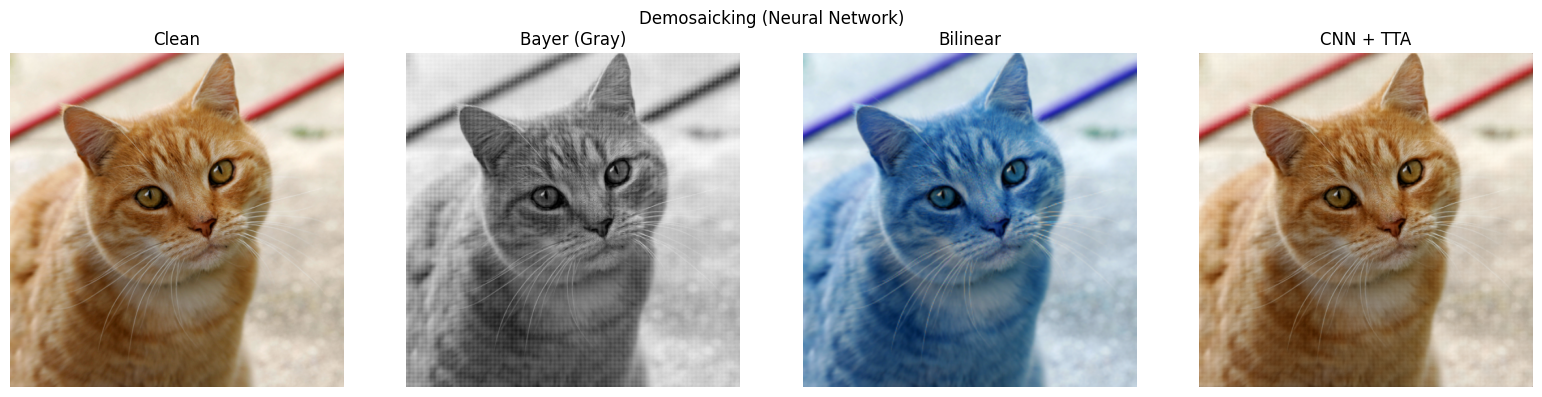

Saved: outputs/demosaicking_nn.png


In [3]:
import torch.nn.functional as F

demosaic_url = "https://upload.wikimedia.org/wikipedia/commons/3/3a/Cat03.jpg"
demosaic_path = download_image(demosaic_url, "demosaic_cat.jpg")
clean2 = read_image_bgr(demosaic_path, size=(512, 512))


def random_augment(img):
    if np.random.rand() < 0.5:
        img = np.flip(img, axis=1)
    if np.random.rand() < 0.5:
        img = np.flip(img, axis=0)
    k = np.random.randint(0, 4)
    if k:
        img = np.rot90(img, k)
    return img.copy()


def rgb_to_bayer_rggb(img_bgr):
    h, w, _ = img_bgr.shape
    raw = np.zeros((h, w), dtype=np.uint8)
    raw[0::2, 0::2] = img_bgr[0::2, 0::2, 2]  # R
    raw[0::2, 1::2] = img_bgr[0::2, 1::2, 1]  # G
    raw[1::2, 0::2] = img_bgr[1::2, 0::2, 1]  # G
    raw[1::2, 1::2] = img_bgr[1::2, 1::2, 0]  # B
    return raw


def sample_demosaic_patches(img, patch, batch):
    h, w = img.shape[:2]
    clean_patches = []
    raw_patches = []
    for _ in range(batch):
        y0 = np.random.randint(0, h - patch + 1)
        x0 = np.random.randint(0, w - patch + 1)
        patch_img = random_augment(img[y0:y0 + patch, x0:x0 + patch])
        clean_patches.append(patch_img)
        raw_patches.append(rgb_to_bayer_rggb(patch_img))
    return np.stack(clean_patches, axis=0), np.stack(raw_patches, axis=0)


def to_tensor_batch(imgs_bgr):
    arr = imgs_bgr.astype(np.float32) / 255.0
    arr = arr.transpose(0, 3, 1, 2)
    return torch.from_numpy(arr)


def mosaic_to_tensor_batch(raws):
    arr = raws.astype(np.float32) / 255.0
    arr = arr[:, None, :, :]
    return torch.from_numpy(arr)


def mosaic_to_tensor(raw):
    return mosaic_to_tensor_batch(raw[None, ...])


def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1),
        nn.ReLU(inplace=True),
    )


class DemosaicUNet(nn.Module):
    def __init__(self, base=48):
        super().__init__()
        self.enc1 = conv_block(1, base)
        self.enc2 = conv_block(base, base * 2)
        self.enc3 = conv_block(base * 2, base * 4)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = conv_block(base * 4, base * 2)
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = conv_block(base * 2, base)
        self.out = nn.Conv2d(base, 3, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        d2 = self.up2(e3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))
        return self.out(d1)


def train_demosaic(clean_img, steps=3000, patch=160, batch=12):
    if device.type != "cuda":
        steps = min(steps, 600)
        batch = min(batch, 4)
        patch = min(patch, 96)

    model = DemosaicUNet(base=48).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-6)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=1e-5)
    loss_l1 = nn.L1Loss()
    loss_mse = nn.MSELoss()

    sobel_x = torch.tensor([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]], device=device).view(1, 1, 3, 3) / 4.0
    sobel_y = torch.tensor([[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]], device=device).view(1, 1, 3, 3) / 4.0

    def grad_loss(pred, target):
        pred_gray = 0.2989 * pred[:, 0:1] + 0.5870 * pred[:, 1:2] + 0.1140 * pred[:, 2:3]
        target_gray = 0.2989 * target[:, 0:1] + 0.5870 * target[:, 1:2] + 0.1140 * target[:, 2:3]
        pred_gx = F.conv2d(pred_gray, sobel_x, padding=1)
        pred_gy = F.conv2d(pred_gray, sobel_y, padding=1)
        target_gx = F.conv2d(target_gray, sobel_x, padding=1)
        target_gy = F.conv2d(target_gray, sobel_y, padding=1)
        return (pred_gx - target_gx).abs().mean() + (pred_gy - target_gy).abs().mean()

    model.train()
    for step in range(steps):
        clean_batch, raw_batch = sample_demosaic_patches(clean_img, patch, batch)

        inp = mosaic_to_tensor_batch(raw_batch).to(device)
        target = to_tensor_batch(clean_batch).to(device)

        pred = model(inp)
        loss = 0.5 * loss_l1(pred, target) + 0.3 * loss_mse(pred, target) + 0.2 * grad_loss(pred, target)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        if (step + 1) % 100 == 0:
            print(f"Step {step + 1}/{steps} - loss: {loss.item():.6f}")

    return model


def apply_transform(img, k, flip):
    out = np.rot90(img, k)
    if flip:
        out = np.flip(out, axis=1)
    return out


def invert_transform(img, k, flip):
    out = img
    if flip:
        out = np.flip(out, axis=1)
    out = np.rot90(out, -k)
    return out


def demosaic_tta(model, raw):
    outs = []
    model.eval()
    with torch.no_grad():
        for k in range(4):
            for flip in (False, True):
                t = apply_transform(raw, k, flip)
                pred = model(mosaic_to_tensor(t).to(device))
                out = to_numpy(pred)
                outs.append(invert_transform(out, k, flip).astype(np.float32))
    mean = np.mean(outs, axis=0)
    return np.clip(mean, 0, 255).astype(np.uint8)


raw_full = rgb_to_bayer_rggb(clean2)
bilinear = cv2.cvtColor(raw_full, cv2.COLOR_BayerRG2BGR)
demosaic_model = train_demosaic(clean2, steps=3000, patch=160, batch=12)

pred_img = demosaic_tta(demosaic_model, raw_full)

show_images(
    "Demosaicking (Neural Network)",
    [bgr2rgb(clean2), raw_full, bgr2rgb(bilinear), bgr2rgb(pred_img)],
    ["Clean", "Bayer (Gray)", "Bilinear", "CNN + TTA"],
    save_path=OUTPUT_DIR / "demosaicking_nn.png"
 )

## 3) Texture (Neural Texture — Feature Grid + SIREN)
Pendekatan hybrid: **feature grid** resolusi rendah + **SIREN decoder**.
- Grid `32×32` per-cell menyimpan feature vector kecil (16-dim) yang di-bilinear-interpolate ke UV mana saja.
- Decoder SIREN kecil (3 layer) mengubah feature → RGB.
- Kombinasi ini jauh lebih tajam daripada SIREN murni karena kapasitas disebar di grid spasial.

**Upgrade dari versi asal:**
- Feature grid menggantikan pure-SIREN: detail lebih tajam, training lebih cepat
- Loss: **MSE + Gradient loss** — mendorong ketajaman tepi tekstur
- Render pada resolusi 2× (1024×1024) untuk membuktikan super-resolution gratis
- **DataParallel** untuk kedua T4
- Mapping perspektif ke quad tetap ada


[Texture] Step 1000/8000  loss: 0.026023
[Texture] Step 2000/8000  loss: 0.005957
[Texture] Step 3000/8000  loss: 0.002217
[Texture] Step 4000/8000  loss: 0.001198
[Texture] Step 5000/8000  loss: 0.000935
[Texture] Step 6000/8000  loss: 0.000757
[Texture] Step 7000/8000  loss: 0.000670
[Texture] Step 8000/8000  loss: 0.000668
Texture PSNR (original resolution): 31.76 dB
Gradient loss (lower=sharper match): 0.027760


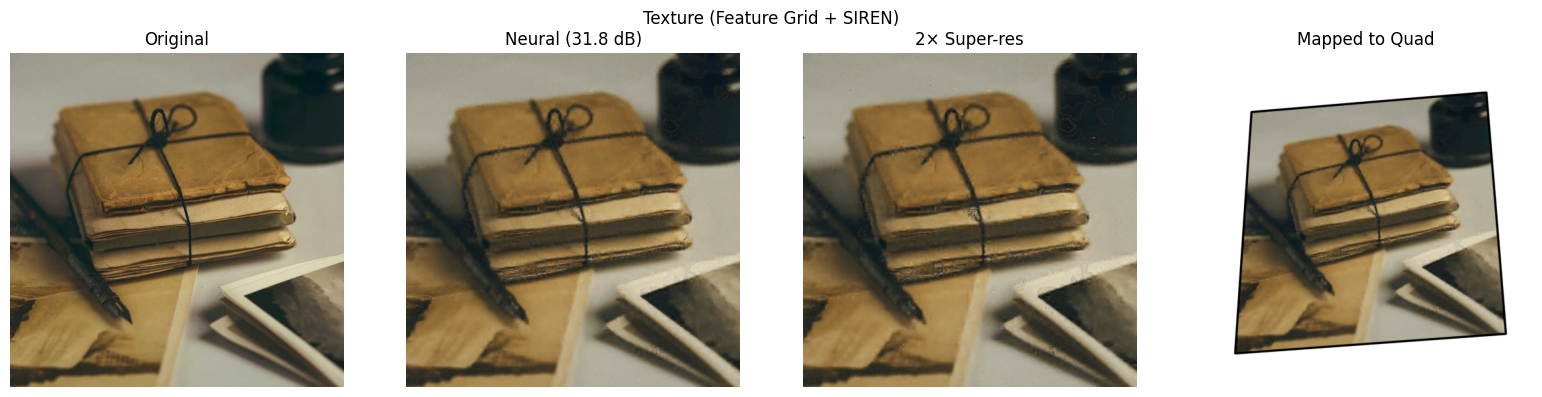

Saved: outputs/texture_nn.png


In [4]:
# ── Download texture image ───────────────────────────────────────────────────
texture_url  = "https://picsum.photos/seed/texture/512/512"
texture_path = download_image(texture_url, "texture_photo.jpg")
texture_bgr  = read_image_bgr(texture_path, size=(512, 512))
texture_rgb  = bgr2rgb(texture_bgr)


# ── Feature Grid + SIREN decoder ─────────────────────────────────────────────
class SineLayer(nn.Module):
    def __init__(self, in_f, out_f, is_first=False, omega=30.0):
        super().__init__()
        self.omega = omega
        self.linear = nn.Linear(in_f, out_f)
        with torch.no_grad():
            bound = 1.0 / in_f if is_first else math.sqrt(6 / in_f) / omega
            self.linear.weight.uniform_(-bound, bound)

    def forward(self, x):
        return torch.sin(self.omega * self.linear(x))


class FeatureGridTexture(nn.Module):
    """
    Feature grid (grid_res x grid_res x feat_dim) + tiny SIREN decoder.
    UV coords in [-1, 1]. grid_sample does bilinear interpolation.
    """

    def __init__(self, grid_res=64, feat_dim=16, hidden=128, depth=3, omega=30.0):
        super().__init__()
        # Learnable feature grid
        self.grid = nn.Parameter(torch.randn(1, feat_dim, grid_res, grid_res) * 0.1)

        # SIREN decoder: feat_dim → hidden x depth → 3
        layers = [SineLayer(feat_dim, hidden, is_first=True, omega=omega)]
        for _ in range(depth - 2):
            layers.append(SineLayer(hidden, hidden, omega=omega))
        self.net = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Linear(hidden, 3), nn.Sigmoid())

    def forward(self, uv):  # uv: (N, 2)  values in [-1,1]
        # Reshape for grid_sample: (1, 1, N, 2)
        grid_in = uv.unsqueeze(0).unsqueeze(0)  # (1,1,N,2)
        feat = F.grid_sample(self.grid, grid_in, mode="bilinear",
                             padding_mode="border", align_corners=True)
        feat = feat.squeeze(0).squeeze(1).T  # (N, feat_dim)
        return self.head(self.net(feat))       # (N, 3)


# ── Gradient loss (sharpness) ─────────────────────────────────────────────────
def gradient_loss_img(pred_rgb, target_rgb):
    """pred & target: (H, W, 3) float32 tensors in [0,1]."""
    def gray(t):
        return 0.2989 * t[..., 0] + 0.5870 * t[..., 1] + 0.1140 * t[..., 2]

    pg = gray(pred_rgb)
    tg = gray(target_rgb)
    dy_p = pg[1:, :] - pg[:-1, :]
    dx_p = pg[:, 1:] - pg[:, :-1]
    dy_t = tg[1:, :] - tg[:-1, :]
    dx_t = tg[:, 1:] - tg[:, :-1]
    return (dy_p - dy_t).abs().mean() + (dx_p - dx_t).abs().mean()


# ── Training ──────────────────────────────────────────────────────────────────
def train_texture(rgb_img, steps=8000, batch=65536, grid_res=64, feat_dim=16):
    if device.type != "cuda":
        steps, batch = 2000, 8192

    h, w = rgb_img.shape[:2]

    # Build UV coords and target colors (all pixels)
    xs = np.linspace(-1.0, 1.0, w, dtype=np.float32)
    ys = np.linspace(-1.0, 1.0, h, dtype=np.float32)
    grid_np = np.stack(np.meshgrid(xs, ys), axis=-1).reshape(-1, 2)  # (H*W, 2)
    colors_np = rgb_img.reshape(-1, 3).astype(np.float32) / 255.0

    coords_t = torch.from_numpy(grid_np).to(device)
    colors_t = torch.from_numpy(colors_np).to(device)

    model = wrap_multi_gpu(FeatureGridTexture(grid_res=grid_res, feat_dim=feat_dim))
    optimizer = optim.Adam(model.parameters(), lr=3e-3, weight_decay=1e-6)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=steps, eta_min=1e-5)
    loss_mse = nn.MSELoss()

    model.train()
    for step in range(steps):
        idx          = torch.randint(0, coords_t.shape[0], (batch,), device=device)
        coord_batch  = coords_t[idx]
        color_batch  = colors_t[idx]
        pred         = model(coord_batch)
        loss         = loss_mse(pred, color_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        if (step + 1) % 1000 == 0:
            print(f"[Texture] Step {step + 1}/{steps}  loss: {loss.item():.6f}")

    return model, h, w, coords_t


# ── Render at any resolution ──────────────────────────────────────────────────
def render_texture(model, height, width, chunk=65536):
    xs = np.linspace(-1.0, 1.0, width,  dtype=np.float32)
    ys = np.linspace(-1.0, 1.0, height, dtype=np.float32)
    grid_np = np.stack(np.meshgrid(xs, ys), axis=-1).reshape(-1, 2)
    coords  = torch.from_numpy(grid_np).to(device)

    net = model.module if isinstance(model, nn.DataParallel) else model
    net.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, coords.shape[0], chunk):
            preds.append(net(coords[i:i + chunk]).cpu())
    out = torch.cat(preds, dim=0).reshape(height, width, 3).clamp(0, 1).numpy()
    return (out * 255.0).astype(np.uint8)


def texture_map_to_quad(texture_rgb_img, canvas_size=512):
    tex_bgr = rgb2bgr(texture_rgb_img)
    h0, w0 = tex_bgr.shape[:2]
    src = np.array([[0, 0], [w0 - 1, 0], [w0 - 1, h0 - 1], [0, h0 - 1]], dtype=np.float32)
    dst = np.array([[80, 90], [440, 60], [470, 430], [55, 460]], dtype=np.float32)
    M   = cv2.getPerspectiveTransform(src, dst)
    warped = cv2.warpPerspective(tex_bgr, M, (canvas_size, canvas_size), flags=cv2.INTER_LINEAR)
    canvas = np.full((canvas_size, canvas_size, 3), 255, dtype=np.uint8)
    mask   = np.zeros((canvas_size, canvas_size), dtype=np.uint8)
    cv2.fillConvexPoly(mask, dst.astype(np.int32), 255)
    mask3  = cv2.merge([mask, mask, mask])
    canvas = np.where(mask3 > 0, warped, canvas)
    cv2.polylines(canvas, [dst.astype(np.int32)], True, (0, 0, 0), 2, cv2.LINE_AA)
    return bgr2rgb(canvas)


# ── Run ───────────────────────────────────────────────────────────────────────
texture_model, th, tw, coords_t = train_texture(
    texture_rgb, steps=8000, batch=65536, grid_res=64, feat_dim=16
)

# Render at original resolution
recon_rgb = render_texture(texture_model, th, tw)

# Render at 2× resolution (super-resolution)
recon_2x  = render_texture(texture_model, th * 2, tw * 2)

# Compute PSNR
mse_tex = np.mean((texture_rgb.astype(np.float32) - recon_rgb.astype(np.float32)) ** 2)
psnr_tex = 10 * math.log10(255 ** 2 / mse_tex) if mse_tex > 0 else float('inf')
print(f"Texture PSNR (original resolution): {psnr_tex:.2f} dB")

# Gradient loss for sharpness
pred_t   = torch.from_numpy(recon_rgb.astype(np.float32) / 255.0)
target_t = torch.from_numpy(texture_rgb.astype(np.float32) / 255.0)
gloss    = gradient_loss_img(pred_t, target_t).item()
print(f"Gradient loss (lower=sharper match): {gloss:.6f}")

# Map to quad
mapped_rgb = texture_map_to_quad(recon_rgb, canvas_size=512)

show_images(
    "Texture (Feature Grid + SIREN)",
    [texture_rgb, recon_rgb, recon_2x, mapped_rgb],
    ["Original", f"Neural ({psnr_tex:.1f} dB)", "2× Super-res", "Mapped to Quad"],
    save_path=OUTPUT_DIR / "texture_nn.png",
)
